# Airbnb business insights — 01 · Data exploration & correlation analysis

1. Load the data and check its quality (missing values, duplicates, data types)
2. Check the data dictionary against the data, and fix columns that are redundant or mislabeled
3. Understand the target variable (price): distribution and outliers, then the level by city
4. Correlation matrix of all attributes (Spearman)
5. Driver strength city by city
6. Guest satisfaction drivers

## 0 · Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter

from common import CORAL, DATA, GRID, INK, LABELS, MUTED, TEAL, load, save, style

style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1 · Raw data & data-quality check

In [2]:
# raw data, exactly as received
raw = pd.read_csv(DATA)
print("Shape:", raw.shape)
raw.head()

Shape: (51707, 21)


,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index,attr_index_norm,rest_index,rest_index_norm,lng,lat,weekday,city
0,121.122322,Private room,False,True,2.0,False,0,0,6.0,69.0,1,5.734117,0.437094,222.882243,15.493414,470.088502,8.413765,-0.04975,51.52570,0,london
1,195.912416,Private room,False,True,2.0,False,1,0,10.0,96.0,1,4.788905,1.464050,235.385841,16.362588,530.133525,9.488466,-0.08475,51.54210,0,london
2,193.325337,Private room,False,True,3.0,False,1,0,10.0,95.0,1,4.596677,0.450306,268.913812,18.693247,548.987610,9.825922,-0.14585,51.54802,0,london
3,180.389943,Private room,False,True,2.0,False,1,0,9.0,87.0,1,2.054769,0.132670,472.381314,32.837067,1021.271062,18.278973,-0.10611,51.52108,0,london
4,405.700981,Entire home/apt,False,False,3.0,False,0,1,7.0,65.0,0,4.491277,0.354108,318.491470,22.139584,692.775411,12.399473,-0.18797,51.49399,0,london


In [3]:
# data type, missing values and number of distinct values per column
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
})
print("Duplicate rows:", raw.duplicated().sum())
quality

Duplicate rows: 0


,dtype,missing,unique
realSum,float64,0,10497
room_type,str,0,3
room_shared,bool,0,2
room_private,bool,0,2
person_capacity,float64,0,5
host_is_superhost,bool,0,2
multi,int64,0,2
biz,int64,0,2
cleanliness_rating,float64,0,9
guest_satisfaction_overall,float64,0,53


## 2 · Check the data dictionary against the data

In [4]:
# are room_shared / room_private just a copy of room_type?
pd.crosstab(raw["room_type"], [raw["room_shared"], raw["room_private"]])

room_shared      False        True 
room_private     False  True  False
room_type                          
Entire home/apt  32648      0     0
Private room         0  18693     0
Shared room          0      0   366

→ Each room type maps to exactly one combination: the two booleans are just a one-hot encoding of `room_type`. **Drop them** (they add no information and would duplicate the signal).

In [5]:
# raw vs. normalised attraction index per city
print(raw.groupby("city")[["attr_index", "attr_index_norm"]].agg(["median", "max"]).round(0))

# how strongly are the raw and normalised indices related (Spearman)?
raw[["attr_index", "attr_index_norm", "rest_index", "rest_index_norm", "dist"]].corr("spearman").round(2)

          attr_index         attr_index_norm       
              median     max          median    max
city                                               
amsterdam      209.0  1889.0            11.0  100.0
athens         119.0  2654.0             4.0  100.0
barcelona      386.0  2934.0            14.0  100.0
berlin          91.0   656.0            14.0  100.0
budapest       200.0  1677.0            12.0  100.0
lisbon         168.0  3032.0             6.0  100.0
london         249.0  1439.0            17.0  100.0
paris          338.0  2057.0            16.0  100.0
rome           406.0  4514.0             9.0  100.0
vienna         104.0  1396.0             7.0  100.0


,attr_index,attr_index_norm,rest_index,rest_index_norm,dist
attr_index,1.00,0.76,0.94,0.66,-0.41
attr_index_norm,0.76,1.00,0.63,0.56,-0.22
rest_index,0.94,0.63,1.00,0.68,-0.38
rest_index_norm,0.66,0.56,0.68,1.00,-0.53
dist,-0.41,-0.22,-0.38,-0.53,1.00


→ The `_norm` versions are scaled to **0–100 within each city** (max = 100 everywhere). The raw index is on a different scale in each city (e.g. median raw attraction index: Rome 406 vs. Berlin 91), so it partly measures *which city you're in*. **The city-normalised versions are kept.** Raw and normalised are strongly correlated (0.76 / 0.68), so keeping both would only add multicollinearity.

## 3 · Cleaned dataset
`load()` applies all decisions from step 2 and adds:
- `is_entire_home`, `is_shared_room`: room type as 0/1, so it can enter a correlation
- `log_price`: the natural log of the price (used because prices are very skewed, see section 4)

In [6]:
# load() is in common.py: it reads the csv and does the cleaning from section 2
df = load()
print(df.shape)
df.head()

(51707, 22)


,price,room_type,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index,attr_index_norm,rest_index,rest_index_norm,lng,lat,weekday,city,is_entire_home,is_shared_room,log_price
0,121.122322,Private room,2.0,0,0,0,6.0,69.0,1,5.734117,0.437094,222.882243,15.493414,470.088502,8.413765,-0.04975,51.52570,0,London,0,0,4.796801
1,195.912416,Private room,2.0,0,1,0,10.0,96.0,1,4.788905,1.464050,235.385841,16.362588,530.133525,9.488466,-0.08475,51.54210,0,London,0,0,5.277668
2,193.325337,Private room,3.0,0,1,0,10.0,95.0,1,4.596677,0.450306,268.913812,18.693247,548.987610,9.825922,-0.14585,51.54802,0,London,0,0,5.264374
3,180.389943,Private room,2.0,0,1,0,9.0,87.0,1,2.054769,0.132670,472.381314,32.837067,1021.271062,18.278973,-0.10611,51.52108,0,London,0,0,5.195121
4,405.700981,Entire home/apt,3.0,0,0,1,7.0,65.0,0,4.491277,0.354108,318.491470,22.139584,692.775411,12.399473,-0.18797,51.49399,0,London,1,0,6.005616


In [7]:
df[["price", "person_capacity", "bedrooms", "cleanliness_rating",
    "guest_satisfaction_overall", "dist", "metro_dist"]].describe().round(1)

,price,person_capacity,bedrooms,cleanliness_rating,guest_satisfaction_overall,dist,metro_dist
count,51707.0,51707.0,51707.0,51707.0,51707.0,51707.0,51707.0
mean,279.9,3.2,1.2,9.4,92.6,3.2,0.7
std,327.9,1.3,0.6,1.0,8.9,2.4,0.9
min,34.8,2.0,0.0,2.0,20.0,0.0,0.0
25%,148.8,2.0,1.0,9.0,90.0,1.5,0.2
50%,211.3,3.0,1.0,10.0,95.0,2.6,0.4
75%,319.7,4.0,1.0,10.0,99.0,4.3,0.7
max,18545.5,6.0,10.0,10.0,100.0,25.3,14.3


In [8]:
counts = df["city"].value_counts()
pd.DataFrame({"listings": counts, "share_%": (counts / len(df) * 100).round(1)})

,listings,share_%
city,,
London,9993,19.3
Rome,9027,17.5
Paris,6688,12.9
Lisbon,5763,11.1
Athens,5280,10.2
Budapest,4022,7.8
Vienna,3537,6.8
Barcelona,2833,5.5
Berlin,2484,4.8


## 4 · Price distribution: why Spearman and log(price)

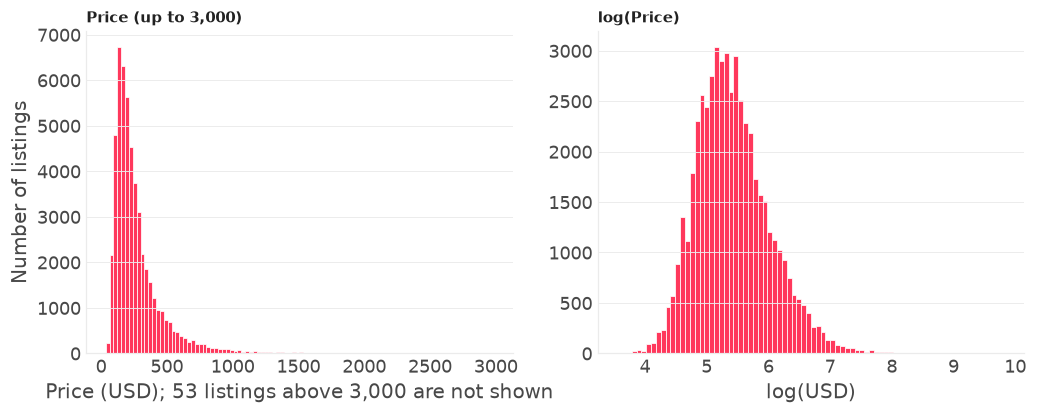

Skewness raw price: 21.4
Skewness log price: 0.71


0.500     211.0
0.900     501.0
0.990    1161.0
0.999    3001.0
Name: price, dtype: float64

In [9]:
# raw price (left) and log of price (right)
n_above = (df["price"] > 3000).sum()    # not shown on the left chart
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df.loc[df["price"] <= 3000, "price"], bins=100, color=CORAL, edgecolor="white", lw=0.5)
axes[0].set_title("Price (up to 3,000)", fontsize=10)
axes[0].set_xlabel(f"Price (USD); {n_above} listings above 3,000 are not shown")
axes[0].set_ylabel("Number of listings")
axes[1].hist(df["log_price"], bins=80, color=CORAL, edgecolor="white", lw=0.5)
axes[1].set_title("log(Price)", fontsize=10)
axes[1].set_xlabel("log(USD)")
for ax in axes:
    ax.grid(axis="x", visible=False)
save(fig, "02_price_distribution")

print("Skewness raw price:", round(df["price"].skew(), 1))
print("Skewness log price:", round(df["log_price"].skew(), 2))
df["price"].quantile([0.5, 0.9, 0.99, 0.999]).round(0)

In [10]:
# how many listings are above each price level
levels = [500, 1000, 2000, 3000, 5000]
pd.DataFrame({
    "listings_above": [(df["price"] > t).sum() for t in levels],
    "share_%": [round((df["price"] > t).mean() * 100, 2) for t in levels],
}, index=[f"> {t:,}" for t in levels])

,listings_above,share_%
> 500,5186,10.03
"> 1,000",771,1.49
"> 2,000",136,0.26
"> 3,000",53,0.10
"> 5,000",26,0.05


## 5 · Price level by city and room type

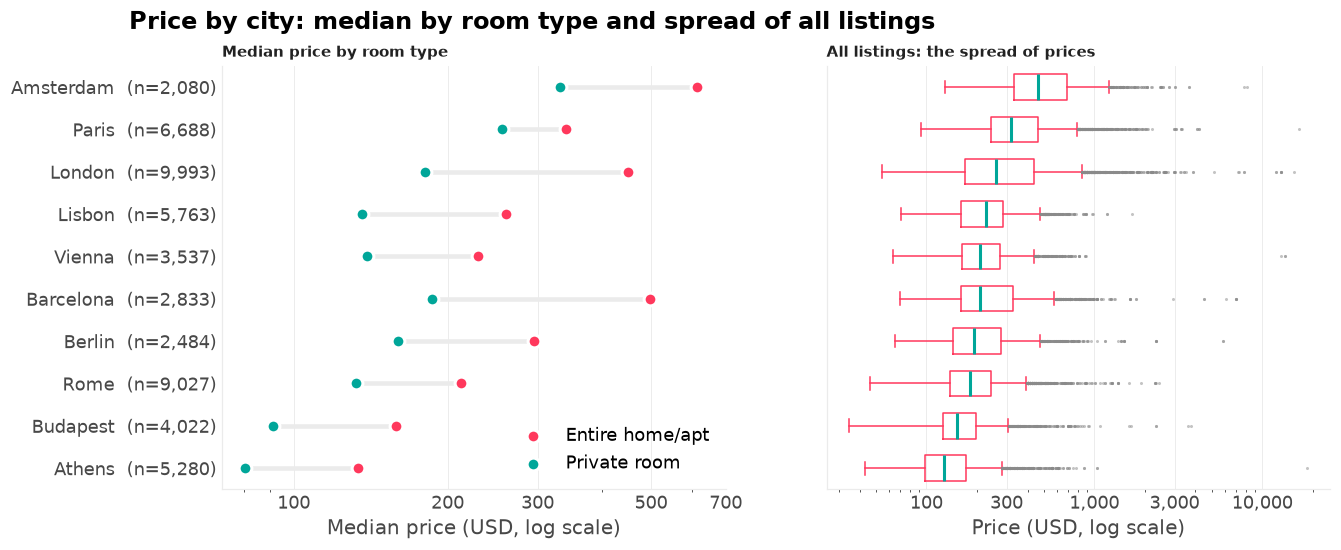

In [11]:
# median price per city and room type
med = df.groupby(["city", "room_type"])["price"].median().unstack()[["Entire home/apt", "Private room"]]
n = df["city"].value_counts()

# same city order in both panels, cheapest at the bottom
order = df.groupby("city")["price"].median().sort_values().index
y = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# left: median price of each room type (log scale)
for room, c in zip(med.columns, [CORAL, TEAL]):
    ax1.scatter(med.loc[order, room], y, s=70, color=c, label=room, zorder=3, edgecolor="white", linewidth=2)
ax1.hlines(y, med.loc[order].min(axis=1), med.loc[order].max(axis=1), color=GRID, lw=3, zorder=2)
ax1.set_xscale("log")
ax1.set_xticks([100, 200, 300, 500, 700])
ax1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax1.xaxis.set_minor_formatter(NullFormatter())
ax1.set_xlabel("Median price (USD, log scale)")
ax1.set_title("Median price by room type", fontsize=10)
ax1.legend(loc="lower right")
ax1.grid(axis="y", visible=False)

# right: spread of all listings in each city (log scale)
prices = [df.loc[df["city"] == c, "price"] for c in order]
ax2.boxplot(prices, positions=y, widths=0.6, orientation="horizontal", showfliers=True,
            flierprops=dict(marker="o", markersize=2, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.5),
            medianprops=dict(color=TEAL, lw=2), boxprops=dict(color=CORAL),
            whiskerprops=dict(color=CORAL), capprops=dict(color=CORAL))
ax2.set_xscale("log")
ax2.set_xticks([100, 300, 1000, 3000, 10000])
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax2.xaxis.set_minor_formatter(NullFormatter())
ax2.set_xlabel("Price (USD, log scale)")
ax2.set_title("All listings: the spread of prices", fontsize=10)
ax2.grid(axis="y", visible=False)

# city names (set after the boxplot, otherwise the axis shows 0-9)
ax1.set_yticks(y, [f"{c}  (n={n[c]:,})" for c in order])

fig.suptitle("Price by city: median by room type and spread of all listings", x=0.06, ha="left", fontweight="bold")
save(fig, "01_price_by_city_roomtype");

## 6 · Correlation matrix of all attributes

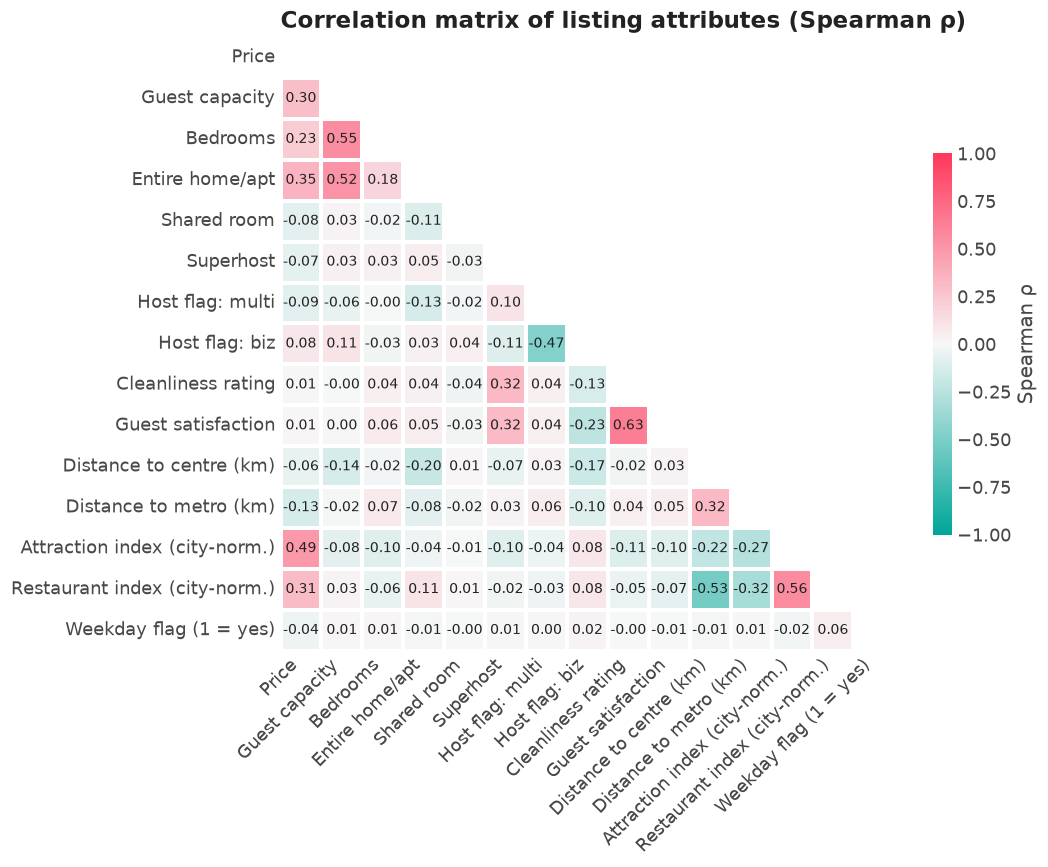

In [12]:
FEATURES = [
    "price", "person_capacity", "bedrooms", "is_entire_home", "is_shared_room",
    "host_is_superhost", "multi", "biz", "cleanliness_rating",
    "guest_satisfaction_overall", "dist", "metro_dist", "attr_index_norm",
    "rest_index_norm", "weekday",
]
# teal = negative, grey = none, coral = positive
DIVERGE = LinearSegmentedColormap.from_list("div", [TEAL, "#f7f7f7", CORAL])

corr = df[FEATURES].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))    # upper half repeats the lower half
labels = [LABELS[c] for c in FEATURES]

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGE, vmin=-1, vmax=1, center=0, annot=True,
            fmt=".2f", annot_kws={"size": 9, "color": INK}, linewidths=1.5,
            linecolor="white", square=True, cbar_kws={"shrink": 0.6, "label": "Spearman ρ"},
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.grid(False)
ax.set_title("Correlation matrix of listing attributes (Spearman ρ)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save(fig, "03_correlation_matrix");

## 7 · Driver strength by city

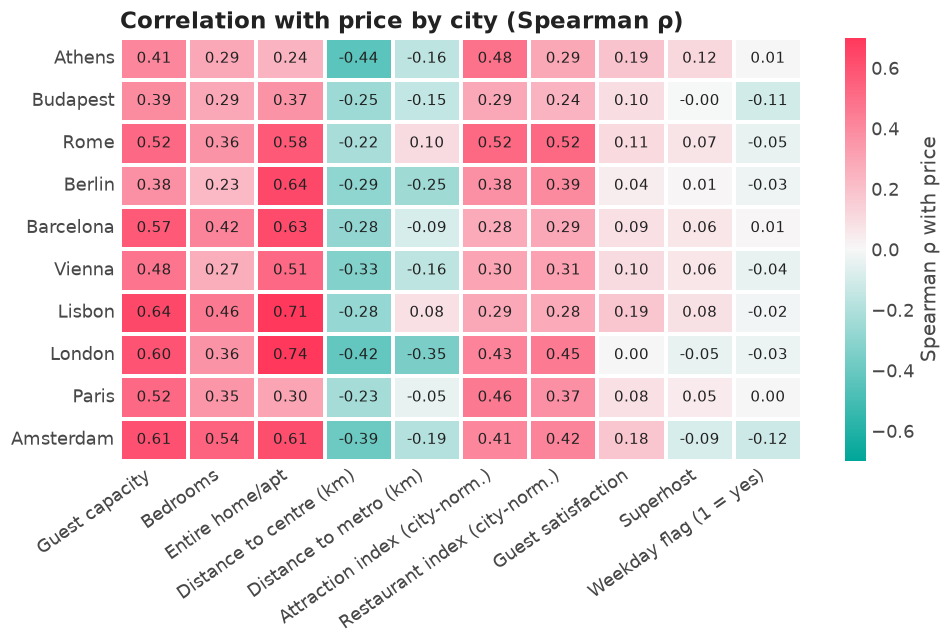

In [13]:
# correlation of each attribute with price, calculated inside each city
columns = ["person_capacity", "bedrooms", "is_entire_home", "dist", "metro_dist",
           "attr_index_norm", "rest_index_norm", "guest_satisfaction_overall",
           "host_is_superhost", "weekday"]
city_order = df.groupby("city")["price"].median().sort_values().index    # cheapest city first

rows = {}
for city in city_order:
    d = df[df["city"] == city]
    rows[city] = d[columns].corrwith(d["price"], method="spearman")
within_city = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(within_city, cmap=DIVERGE, vmin=-0.7, vmax=0.7, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 10, "color": INK}, linewidths=1.5, linecolor="white",
            xticklabels=[LABELS[c] for c in columns], cbar_kws={"label": "Spearman ρ with price"}, ax=ax)
ax.grid(False)
ax.set_ylabel("")
ax.set_title("Correlation with price by city (Spearman ρ)")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
save(fig, "05_drivers_by_city");

## 8 · Guest satisfaction: what goes with happy guests?

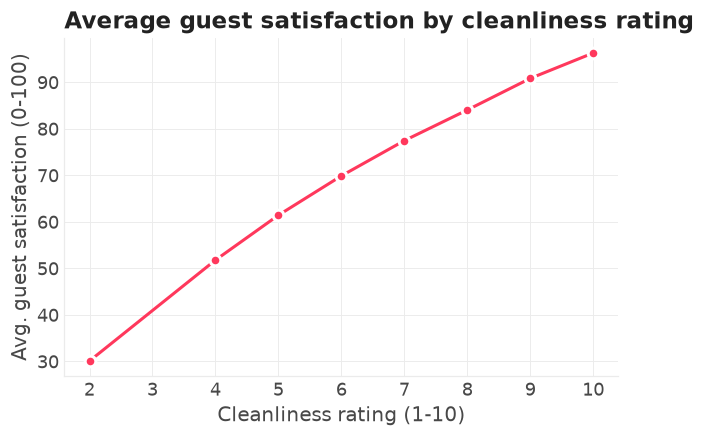

In [14]:
# average satisfaction for each cleanliness rating
clean = df.groupby("cleanliness_rating")["guest_satisfaction_overall"].agg(["mean", "size"])
clean = clean[clean["size"] >= 50]    # rating 3 has only 10 listings

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(clean.index, clean["mean"], color=CORAL, lw=2, marker="o", ms=7,
        markeredgecolor="white", markeredgewidth=2)
ax.set_xlabel("Cleanliness rating (1-10)")
ax.set_ylabel("Avg. guest satisfaction (0-100)")
ax.set_title("Average guest satisfaction by cleanliness rating")
save(fig, "06_satisfaction_drivers");

In [15]:
# superhosts vs. regular hosts
by_host = df.groupby("host_is_superhost").agg(
    median_price=("price", "median"),
    avg_satisfaction=("guest_satisfaction_overall", "mean"),
    avg_cleanliness=("cleanliness_rating", "mean"),
)
by_host["share_of_listings_%"] = df["host_is_superhost"].value_counts(normalize=True) * 100
by_host.rename(index={0: "Regular host", 1: "Superhost"}).round(1)

,median_price,avg_satisfaction,avg_cleanliness,share_of_listings_%
host_is_superhost,,,,
Regular host,217.5,91.2,9.2,74.4
Superhost,197.0,96.9,9.8,25.6
